# 03 LightGBM
Gradient-boosted decision trees, trained with absolute error (`objective="l1"`), compared against the Day 2 baselines on the validation year (Jul 2024 to Jun 2025).

LightGBM builds hundreds of small decision trees one after another; each new tree corrects the errors of the ones before. Unlike the linear models, trees can capture non-linear effects (e.g. "high recent prices AND evening peak means a much higher price").

In [1]:
import sys
sys.path.append("../src")                       # Python finds src/forecasting.py

import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from forecasting import (FEATURES, FEATURES_NO_WEATHER, TEST_START, VAL_START, VAL_END,
                         load_model_data, evaluate, walk_forward)

df = load_model_data()
# Day 2's validation predictions, reloaded so the baselines don't need re-running
baseline_preds = pd.read_parquet("../results/validation_predictions.parquet")
print(f"Rows usable for modelling: {len(df):,}")

Rows usable for modelling: 59,424


## Model settings
Three sizes are compared on the validation year:
- `num_leaves`: how many end-points each tree has (bigger = each tree captures more detailed patterns)
- `n_estimators`: how many trees are built in total
- `learning_rate`: how much each new tree is allowed to correct the previous ones (smaller = slower)

In [9]:
def make_lightgbm(features=FEATURES, **params):
    """Build a fit_predict function for walk_forward, using LightGBM with absolute-error loss.
    `features` picks which columns the model sees; `**params` passes settings like num_leaves."""
    def fit_predict(train, test):
        model = lgb.LGBMRegressor(objective="l1", random_state=42, verbose=-1, **params)
        model.fit(train[features], train["price"])
        return model.predict(test[features])
    return fit_predict


# Three model sizes to compare
CONFIGS = {
    "small":  dict(num_leaves=15, n_estimators=300, learning_rate=0.05),
    "medium": dict(num_leaves=31, n_estimators=500, learning_rate=0.05),
    "large":  dict(num_leaves=63, n_estimators=800, learning_rate=0.03),
}

In [10]:
# Walk forward validation for each model size, using the same date range and features
lgbm_preds = pd.DataFrame({
    "LightGBM small":  walk_forward(df, make_lightgbm(**CONFIGS["small"]),  VAL_START, VAL_END),
    "LightGBM medium": walk_forward(df, make_lightgbm(**CONFIGS["medium"]), VAL_START, VAL_END),
    "LightGBM large":  walk_forward(df, make_lightgbm(**CONFIGS["large"]),  VAL_START, VAL_END),
})

  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done
  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done
  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done


## Results: all models, validation year

In [12]:
# Put the Day 2 baselines and LightGBM side by side
all_preds = pd.concat([baseline_preds, lgbm_preds], axis=1)
val = df.loc[all_preds.index]          # the validation rows, lined up with the predictions


def score(preds):
    """Score every column of a predictions table; one row per model."""
    return preds.apply(lambda p: evaluate(val["price"], p, val["date"])).T.round(2)


score(all_preds)

,MAE,RMSE,Spearman
Model 0 Naive (yesterday),56.90,124.33,0.38
Model 1 Weekly naive (last week),89.18,160.11,0.32
Model 2a Linear (least squares),49.93,95.65,0.52
Model 2b Linear (absolute error),48.44,95.79,0.52
LightGBM small,57.02,116.67,0.48
LightGBM medium,56.67,114.31,0.48
LightGBM large,55.80,110.55,0.48


## Where does LightGBM lose?
LightGBM large is behind the linear model (absolute error) overall. Comparing mean absolute error month by month shows where.

In [13]:
# Mean absolute error per month for the two models being compared
compare = all_preds[["Model 2b Linear (absolute error)", "LightGBM large"]]
monthly_mae = (compare.sub(val["price"], axis=0)                       # forecast minus actual
                      .abs()                                           # absolute errors
                      .groupby(val["date"].dt.to_period("M")).mean()   # average per month
                      .round(1))
monthly_mae.index = monthly_mae.index.strftime("%m/%Y")
monthly_mae

,Model 2b Linear (absolute error),LightGBM large
date,,
07/2024,57.2,69.9
08/2024,104.3,168.6
09/2024,52.4,50.6
10/2024,33.8,35.5
11/2024,28.7,28.2
12/2024,32.4,33.1
01/2025,29.2,28.7
02/2025,55.9,61.0
03/2025,45.8,45.2


LightGBM is within about \$2/MWh of the linear model in 9 of 12 months. Roughly 85 to 90% of the overall gap comes from **July and August 2024**, the price crisis, when prices went beyond anything in the training data. Tree models can't predict outside the range of prices they were trained on; linear models can scale up with recent prices.

## Attempted fix 1: predict the change, not the level
Train LightGBM on the difference between the price and a recent level, then add the level back, so the forecast can follow prices into new highs.

In [14]:
def make_lightgbm_relative(base_col, features=FEATURES, **params):
    """LightGBM that predicts the DIFFERENCE from a recent price level (base_col),
    then adds that level back. Lets the forecast follow prices into new highs or lows."""
    def fit_predict(train, test):
        model = lgb.LGBMRegressor(objective="l1", random_state=42, verbose=-1, **params)
        model.fit(train[features], train["price"] - train[base_col])     # learn: price minus recent level
        return test[base_col] + model.predict(test[features])            # predict: recent level plus difference
    return fit_predict


relative_preds = pd.DataFrame({
    "LightGBM large, relative to 7-day average": walk_forward(
        df, make_lightgbm_relative("tp_mean_7d", **CONFIGS["large"]), VAL_START, VAL_END),
    "LightGBM large, relative to yesterday": walk_forward(
        df, make_lightgbm_relative("lag_1d", **CONFIGS["large"]), VAL_START, VAL_END),
})
score(relative_preds)

  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done
  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done


,MAE,RMSE,Spearman
"LightGBM large, relative to 7-day average",58.14,116.28,0.44
"LightGBM large, relative to yesterday",58.13,123.75,0.47


This made things slightly worse, so it was not used.

## Attempted fix 2: remove the month feature
With only about 18 months of training data at the start, each calendar month has been seen once or twice. Trees can memorise month-specific price levels that don't carry over to another year.

In [15]:
BEST = "large"                                              # best size from Cell 4
FINAL_FEATURES = list(pd.Index(FEATURES).drop("month"))     # final LightGBM feature set

final_preds = walk_forward(df, make_lightgbm(features=FINAL_FEATURES, **CONFIGS[BEST]),
                           VAL_START, VAL_END)
evaluate(val["price"], final_preds, val["date"]).round(2)

  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done


MAE          54.66
RMSE        109.42
Spearman      0.47
dtype: float64

Removing `month` improved MAE slightly (\$55.80 to \$54.66), so the **final LightGBM is the large model without `month`**.

## Does the weather help?
The weather features use day D's **actual** weather, which wouldn't be known when forecasting the day before. If removing them barely changes accuracy, they can be dropped, which removes that shortcut entirely.

In [16]:
final_no_weather = list(pd.Index(FINAL_FEATURES).drop(["akl_temp", "mnw_wind"]))

weather_check = pd.DataFrame({
    "LightGBM final (with weather)": final_preds,
    "LightGBM final (no weather)": walk_forward(
        df, make_lightgbm(features=final_no_weather, **CONFIGS[BEST]), VAL_START, VAL_END),
})
score(weather_check)

  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done


,MAE,RMSE,Spearman
LightGBM final (with weather),54.66,109.42,0.47
LightGBM final (no weather),58.12,115.89,0.47


## What does the final model rely on?
Feature importance ("gain") = each feature's share of the model's total error reduction. Trained on all data before the test year.

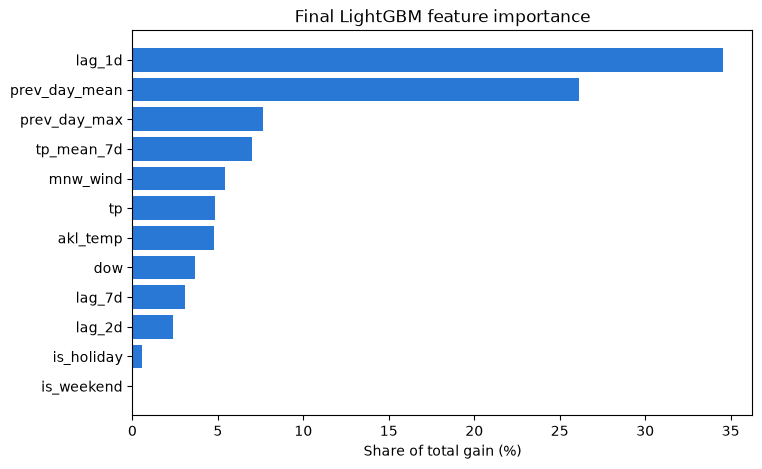

In [17]:
BLUE = "#2a78d6"

pre_test = df[df["date"] < TEST_START]            # everything before the test year
final_model = lgb.LGBMRegressor(objective="l1", random_state=42, verbose=-1, **CONFIGS[BEST])
final_model.fit(pre_test[FINAL_FEATURES], pre_test["price"])

# Each feature's share of the total gain, as a percentage, sorted smallest to largest
importance = pd.Series(final_model.booster_.feature_importance(importance_type="gain"), index=FINAL_FEATURES)
importance = (importance / importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=BLUE)
ax.set_title("Final LightGBM feature importance")
ax.set_xlabel("Share of total gain (%)")
fig.savefig("../results/figures/07_feature_importance.png", dpi=150, bbox_inches="tight")

In [18]:
# Save every LightGBM validation run, and one combined results table for all models
lightgbm_val = pd.concat([lgbm_preds, relative_preds, weather_check], axis=1)
lightgbm_val.to_parquet("../results/validation_predictions_lightgbm.parquet")
score(pd.concat([baseline_preds, lightgbm_val], axis=1)).to_csv("../results/validation_results_all.csv")